**Data Loading & Data Understanding**


In [78]:
#Loading Data dan Membaca Data

import pandas as pd
#Membaca Dataset
df = pd.read_csv("transaction_data.csv")

In [79]:
# Memeriksa Struktur Dataset

# Informasi umum dataset
print("DATASET INFORMATION")
print("Shape:", df.shape)

print("\n FIRST 5 ROWS")
display(df.head())

print("\n DATA TYPES")
print(df.dtypes)

print("\n STATISTICAL SUMMARY")
display(df.describe().T)

DATASET INFORMATION
Shape: (2595732, 12)

 FIRST 5 ROWS


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0



 DATA TYPES
household_key          int64
BASKET_ID              int64
DAY                    int64
PRODUCT_ID             int64
QUANTITY               int64
SALES_VALUE          float64
STORE_ID               int64
RETAIL_DISC          float64
TRANS_TIME             int64
WEEK_NO                int64
COUPON_DISC          float64
COUPON_MATCH_DISC    float64
dtype: object

 STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
household_key,2595732.0,1.271953e+03,7.260660e+02,1.000000e+00,6.560000e+02,1.272000e+03,1.913000e+03,2.500000e+03
BASKET_ID,2595732.0,3.402620e+10,4.711649e+09,2.698485e+10,3.040805e+10,3.276081e+10,4.012685e+10,4.230536e+10
DAY,2595732.0,3.887562e+02,1.897210e+02,1.000000e+00,2.290000e+02,3.900000e+02,5.530000e+02,7.110000e+02
PRODUCT_ID,2595732.0,2.891435e+06,3.837404e+06,2.567100e+04,9.174590e+05,1.028816e+06,1.133018e+06,1.831630e+07
QUANTITY,2595732.0,1.004286e+02,1.153436e+03,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,8.963800e+04
SALES_VALUE,2595732.0,3.104120e+00,4.182274e+00,0.000000e+00,1.290000e+00,2.000000e+00,3.490000e+00,8.400000e+02
STORE_ID,2595732.0,3.142673e+03,8.937113e+03,1.000000e+00,3.300000e+02,3.720000e+02,4.220000e+02,3.428000e+04
RETAIL_DISC,2595732.0,-5.387054e-01,1.249191e+00,-1.800000e+02,-6.900000e-01,-1.000000e-02,0.000000e+00,3.990000e+00
TRANS_TIME,2595732.0,1.561586e+03,3.998378e+02,0.000000e+00,1.308000e+03,1.613000e+03,1.843000e+03,2.359000e+03
WEEK_NO,2595732.0,5.622150e+01,2.710223e+01,1.000000e+00,3.300000e+01,5.600000e+01,8.000000e+01,1.020000e+02


In [80]:
# Memerriksa Cakupan DATA
data_summary = {
    "Total Rows": len(df),
    "Total Columns": len(df.columns),
    "Unique Households": df["household_key"].nunique(),
    "Unique Baskets": df["BASKET_ID"].nunique(),
    "Unique Products": df["PRODUCT_ID"].nunique(),
    "Unique Stores": df["STORE_ID"].nunique(),
    "Unique Days": df["DAY"].nunique(),
    "Unique Weeks": df["WEEK_NO"].nunique(),
    "Min Day": df["DAY"].min(),
    "Max Day": df["DAY"].max(),
    "Min Week": df["WEEK_NO"].min(),
    "Max Week": df["WEEK_NO"].max()
}

summary_df = pd.DataFrame(
    data_summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total Rows,2595732
1,Total Columns,12
2,Unique Households,2500
3,Unique Baskets,276484
4,Unique Products,92339
5,Unique Stores,582
6,Unique Days,711
7,Unique Weeks,102
8,Min Day,1
9,Max Day,711


In [81]:
#Meriksa Qualitas Data
quality_check = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(quality_check)

print("Duplicate rows:", df.duplicated().sum())

,Data Type,Missing Values,Missing (%),Unique Values
household_key,int64,0,0.0,2500
BASKET_ID,int64,0,0.0,276484
DAY,int64,0,0.0,711
PRODUCT_ID,int64,0,0.0,92339
QUANTITY,int64,0,0.0,11746
SALES_VALUE,float64,0,0.0,5502
STORE_ID,int64,0,0.0,582
RETAIL_DISC,float64,0,0.0,2414
TRANS_TIME,int64,0,0.0,1440
WEEK_NO,int64,0,0.0,102


Duplicate rows: 0


#Data Understanding


In [82]:
# Memeriksa nilai transaksi yang tidak biasa

transaction_check = pd.DataFrame({
    "Metric": [
        "Zero SALES_VALUE",
        "Negative SALES_VALUE",
        "Zero QUANTITY",
        "Negative QUANTITY",
        "Positive SALES_VALUE",
        "Positive QUANTITY"
    ],
    "Count": [
        (df["SALES_VALUE"] == 0).sum(),
        (df["SALES_VALUE"] < 0).sum(),
        (df["QUANTITY"] == 0).sum(),
        (df["QUANTITY"] < 0).sum(),
        (df["SALES_VALUE"] > 0).sum(),
        (df["QUANTITY"] > 0).sum()
    ]
})

transaction_check["Percentage (%)"] = (
    transaction_check["Count"] / len(df) * 100
).round(2)

display(transaction_check)

,Metric,Count,Percentage (%)
0,Zero SALES_VALUE,18850,0.73
1,Negative SALES_VALUE,0,0.00
2,Zero QUANTITY,14466,0.56
3,Negative QUANTITY,0,0.00
4,Positive SALES_VALUE,2576882,99.27
5,Positive QUANTITY,2581266,99.44


Nilai nol pada suatu baris produk belum tentu menunjukkan transaksi tidak valid.

In [83]:
#Memeriksa konsistensi basket
basket_check = (
    df.groupby("BASKET_ID")
      .agg(
          households=("household_key", "nunique"),
          days=("DAY", "nunique"),
          stores=("STORE_ID", "nunique"),
          weeks=("WEEK_NO", "nunique")
      )
      .reset_index()
)

inconsistent_baskets = basket_check[
    (basket_check["households"] > 1) |
    (basket_check["days"] > 1) |
    (basket_check["stores"] > 1) |
    (basket_check["weeks"] > 1)
]

print("Total unique baskets:", len(basket_check))
print("Inconsistent baskets:", len(inconsistent_baskets))

display(inconsistent_baskets.head(10))

Total unique baskets: 276484
Inconsistent baskets: 0


,BASKET_ID,households,days,stores,weeks


Setiap BASKET_ID hanya terkait dengan satu household, satu hari, satu toko, dan satu minggu.

In [84]:
#Memeriksa hubungan DAY dan WEEK_NO
day_week_check = (
    df.groupby("WEEK_NO")
      .agg(
          min_day=("DAY", "min"),
          max_day=("DAY", "max"),
          unique_days=("DAY", "nunique"),
          total_baskets=("BASKET_ID", "nunique"),
          total_households=("household_key", "nunique"),
          total_sales=("SALES_VALUE", "sum")
      )
      .reset_index()
)

display(day_week_check)


,WEEK_NO,min_day,max_day,unique_days,total_baskets,total_households,total_sales
0,1,1,5,5,142,88,5211.16
1,2,6,12,7,324,175,10821.35
2,3,13,19,7,482,228,13498.20
3,4,20,26,7,545,270,15965.99
4,5,27,33,7,757,370,20139.82
...,...,...,...,...,...,...,...
97,98,678,684,7,3037,1384,98949.62
98,99,685,691,7,2851,1325,101363.92
99,100,692,698,7,2793,1313,93063.10
100,101,699,705,7,2682,1269,84407.25


DATA CLEANING AND PREPARATION

In [85]:
#Memeriksa kombinasi nilai nol
zero_analysis = pd.DataFrame({
    "Condition": [
        "SALES_VALUE = 0 and QUANTITY = 0",
        "SALES_VALUE = 0 and QUANTITY > 0",
        "SALES_VALUE > 0 and QUANTITY = 0",
        "SALES_VALUE > 0 and QUANTITY > 0"
    ],
    "Count": [
        ((df["SALES_VALUE"] == 0) & (df["QUANTITY"] == 0)).sum(),
        ((df["SALES_VALUE"] == 0) & (df["QUANTITY"] > 0)).sum(),
        ((df["SALES_VALUE"] > 0) & (df["QUANTITY"] == 0)).sum(),
        ((df["SALES_VALUE"] > 0) & (df["QUANTITY"] > 0)).sum()
    ]
})

zero_analysis["Percentage (%)"] = (
    zero_analysis["Count"] / len(df) * 100
).round(2)

display(zero_analysis)

,Condition,Count,Percentage (%)
0,SALES_VALUE = 0 and QUANTITY = 0,14399,0.55
1,SALES_VALUE = 0 and QUANTITY > 0,4451,0.17
2,SALES_VALUE > 0 and QUANTITY = 0,67,0.00
3,SALES_VALUE > 0 and QUANTITY > 0,2576815,99.27


In [86]:
#Melihat contoh baris dengan nilai nol
zero_sales = df[df["SALES_VALUE"] == 0]

display(
    zero_sales[
        [
            "household_key",
            "BASKET_ID",
            "DAY",
            "PRODUCT_ID",
            "QUANTITY",
            "SALES_VALUE",
            "RETAIL_DISC",
            "COUPON_DISC",
            "COUPON_MATCH_DISC"
        ]
    ].head(15)
)

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_DISC,COUPON_MATCH_DISC
97,744,26985165432,1,5978648,0,0.0,0.00,0.0,0.0
128,1287,26985336468,1,5978648,0,0.0,0.00,0.0,0.0
249,2305,26996870743,2,5978656,0,0.0,0.00,-1.0,0.0
293,271,26997082949,2,5978656,0,0.0,0.00,-2.0,0.0
694,315,27008952267,3,957951,0,0.0,0.00,0.0,0.0
766,2110,27009082349,3,837963,1,0.0,0.00,0.0,0.0
996,568,27021090189,4,951412,1,0.0,-1.48,0.0,0.0
1089,14,27021203242,4,6463658,0,0.0,0.00,0.0,0.0
1095,2110,27021248054,4,850115,1,0.0,-3.29,0.0,0.0
1113,2110,27021248054,4,976872,1,0.0,-2.49,0.0,0.0


Ada beberapa baris dengan SALES_VALUE = 0 tetapi QUANTITY > 0, bahkan sebagian memiliki diskon negatif. Ini bisa mengindikasikan produk gratis atau transaksi yang seluruh harganya tertutup diskon.


In [87]:
#Memeriksa distribusi nilai RFM awal
print("=== RFM SOURCE VARIABLES ===")

print("\nSALES_VALUE:")
display(df["SALES_VALUE"].describe())

print("\nBASKET_ID per household:")
display(
    df.groupby("household_key")["BASKET_ID"]
      .nunique()
      .describe()
)

print("\nLast purchase DAY per household:")
display(
    df.groupby("household_key")["DAY"]
      .max()
      .describe()
)

=== RFM SOURCE VARIABLES ===

SALES_VALUE:


,SALES_VALUE
count,2.595732e+06
mean,3.104120e+00
std,4.182274e+00
min,0.000000e+00
25%,1.290000e+00
50%,2.000000e+00
75%,3.490000e+00
max,8.400000e+02



BASKET_ID per household:


,BASKET_ID
count,2500.000000
mean,110.593600
std,115.669368
min,1.000000
25%,39.000000
50%,79.000000
75%,142.250000
max,1300.000000



Last purchase DAY per household:


,DAY
count,2500.000000
mean,685.426000
std,62.790655
min,54.000000
25%,691.000000
50%,705.000000
75%,710.000000
max,711.000000


- Terdapat variasi aktivitas pembelian yang cukup besar antarrumah tangga.
- Sebagian besar household masih bertransaksi mendekati akhir periode observasi.


In [88]:
# Menghitung total sales untuk setiap basket
basket_analysis = (
    df.groupby(["household_key", "BASKET_ID"])
      .agg(
          basket_sales=("SALES_VALUE", "sum"),
          total_items=("QUANTITY", "sum"),
          total_rows=("PRODUCT_ID", "count")
      )
      .reset_index()
)

# Mengidentifikasi basket dengan total sales nol
zero_baskets = basket_analysis[
    basket_analysis["basket_sales"] == 0
]

print("Total unique baskets:", len(basket_analysis))
print("Baskets with zero total sales:", len(zero_baskets))
print(
    "Percentage of zero-sales baskets:",
    round(len(zero_baskets) / len(basket_analysis) * 100, 2),
    "%"
)

print("\nSample zero-sales baskets:")
display(zero_baskets.head(10))

Total unique baskets: 276484
Baskets with zero total sales: 942
Percentage of zero-sales baskets: 0.34 %

Sample zero-sales baskets:


,household_key,BASKET_ID,basket_sales,total_items,total_rows
37,1,32730551099,0.0,0,1
315,6,31007737040,0.0,0,1
989,14,27609862573,0.0,0,1
1095,14,36028048901,0.0,0,1
1469,18,32872502191,0.0,0,1
1506,18,40085216046,0.0,0,2
2101,20,32259655145,0.0,1,1
2116,20,32556002223,0.0,1,1
2168,20,33293456132,0.0,1,1
2227,20,34837255131,0.0,1,1


In [89]:
print("Total unique baskets:", len(basket_analysis))

print(
    "Zero-sales baskets:",
    len(zero_baskets)
)

print(
    "Zero-sales baskets with zero quantity:",
    (zero_baskets["total_items"] == 0).sum()
)

print(
    "Zero-sales baskets with positive quantity:",
    (zero_baskets["total_items"] > 0).sum()
)

print(
    "Positive-sales baskets:",
    (basket_analysis["basket_sales"] > 0).sum()
)

Total unique baskets: 276484
Zero-sales baskets: 942
Zero-sales baskets with zero quantity: 592
Zero-sales baskets with positive quantity: 350
Positive-sales baskets: 275542


In [90]:
# Membentuk RFM
# Menghitung total sales untuk setiap basket
basket_rfm = (
    df.groupby(
        ["household_key", "BASKET_ID", "DAY"],
        as_index=False
    )
    .agg(
        basket_sales=("SALES_VALUE", "sum")
    )
)

# Hanya menggunakan basket dengan total sales positif
basket_rfm = basket_rfm[
    basket_rfm["basket_sales"] > 0
].copy()

print("Total qualifying baskets:", len(basket_rfm))
print("Unique households:", basket_rfm["household_key"].nunique())

display(basket_rfm.head())

Total qualifying baskets: 275542
Unique households: 2500


,household_key,BASKET_ID,DAY,basket_sales
0,1,27601281299,51,78.66
1,1,27774192959,67,41.10
2,1,28024266849,88,26.90
3,1,28106322445,94,63.43
4,1,28235481967,101,53.45


In [91]:
# Menghitung RFM per household
rfm = (
    basket_rfm.groupby("household_key")
    .agg(
        last_purchase_day=("DAY", "max"),
        Frequency=("BASKET_ID", "nunique"),
        Monetary=("basket_sales", "sum")
    )
    .reset_index()
)

# Reference day = 712
rfm["Recency"] = 712 - rfm["last_purchase_day"]

# Menampilkan kolom RFM
rfm = rfm[
    ["household_key", "Recency", "Frequency", "Monetary"]
]

print("Total households in RFM:", len(rfm))
display(rfm.head(10))

Total households in RFM: 2500


,household_key,Recency,Frequency,Monetary
0,1,6,85,4330.16
1,2,44,45,1954.34
2,3,9,47,2653.21
3,4,85,30,1200.11
4,5,9,40,779.06
5,6,5,249,5996.16
6,7,3,59,3400.05
7,8,6,113,5534.97
8,9,23,20,797.42
9,10,27,9,234.34


Seluruh 2.500 household berhasil masuk ke tabel RFM, tidak ada missing values, dan tidak ada household duplikat.

In [92]:
print("=== RFM SUMMARY ===")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())

print("\n=== DATA VALIDATION ===")
print("Missing values:")
display(rfm.isnull().sum())

print("Duplicate households:", rfm["household_key"].duplicated().sum())
print("Minimum Recency:", rfm["Recency"].min())
print("Maximum Recency:", rfm["Recency"].max())
print("Minimum Frequency:", rfm["Frequency"].min())
print("Minimum Monetary:", rfm["Monetary"].min())

=== RFM SUMMARY ===


,Recency,Frequency,Monetary
count,2500.000000,2500.000000,2500.000000
mean,26.576000,110.216800,3222.985232
std,62.791673,115.271537,3349.026076
min,1.000000,1.000000,8.170000
25%,2.000000,38.000000,970.740000
50%,7.000000,78.000000,2157.750000
75%,21.000000,142.000000,4413.320000
max,658.000000,1298.000000,38319.790000



=== DATA VALIDATION ===
Missing values:


,0
household_key,0
Recency,0
Frequency,0
Monetary,0


Duplicate households: 0
Minimum Recency: 1
Maximum Recency: 658
Minimum Frequency: 1
Minimum Monetary: 8.17


Recency
- Median hanya 7 hari, artinya separuh household terakhir berbelanja dalam 7 hari atau kurang sebelum akhir periode observasi.
- Rata-rata 26,58 hari jauh lebih besar daripada median.
- Ada household yang sudah tidak berbelanja selama 658 hari.
Distribusi Recency kemungkinan right-skewed (miring ke kanan)

Frequency
- Median 78 basket, sedangkan rata-rata 110,22 basket.
- Ada household dengan 1.298 basket.
- Ini menunjukkan perbedaan aktivitas pembelian yang cukup besar.

Monetary
- Median pengeluaran tercatat sebesar 2.157,75.
- Rata-rata sebesar 3.222,99.
- Nilai maksimum mencapai 38.319,79.

Monetary juga kemungkinan memiliki distribusi right-skewed. Karena itu, kita tidak sebaiknya menggunakan pembagian skor berdasarkan interval yang sama besar.


In [93]:
# Quantile analysis
quantiles = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

for col in ["Recency", "Frequency", "Monetary"]:
    print(f"\n=== {col} ===")

    print("Unique values:", rfm[col].nunique())

    print("\nQuantile boundaries:")
    display(rfm[col].quantile(quantiles))

    print("\nMost frequent values:")
    display(rfm[col].value_counts().head(10))


=== Recency ===
Unique values: 200

Quantile boundaries:


,Recency
0.0,1.0
0.2,2.0
0.4,5.0
0.6,10.0
0.8,28.0
1.0,658.0



Most frequent values:


,count
Recency,
1,367
2,262
3,194
4,157
7,117
6,116
5,109
8,85
9,61



=== Frequency ===
Unique values: 395

Quantile boundaries:


,Frequency
0.0,1.0
0.2,32.0
0.4,59.0
0.6,99.0
0.8,162.2
1.0,1298.0


... (2 outputs left out)


=== Monetary ===
Unique values: 2494

Quantile boundaries:


,Monetary
0.0,8.170
0.2,760.802
0.4,1634.814
0.6,2766.808
0.8,5083.860
1.0,38319.790



Most frequent values:


,count
Monetary,
1934.45,2
2283.69,2
5097.28,2
226.71,2
2542.45,2
2588.73,2
647.90,1
2820.61,1
2045.50,1


In [94]:
#Membuat skor RFM

# Membuat salinan tabel RFM
rfm_score = rfm.copy()

# Recency: nilai lebih kecil mendapatkan skor lebih tinggi
rfm_score["R_Score"] = pd.qcut(
    rfm_score["Recency"],
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: nilai lebih besar mendapatkan skor lebih tinggi
rfm_score["F_Score"] = pd.qcut(
    rfm_score["Frequency"],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: nilai lebih besar mendapatkan skor lebih tinggi
rfm_score["M_Score"] = pd.qcut(
    rfm_score["Monetary"],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Menggabungkan skor menjadi RFM Score
rfm_score["RFM_Score"] = (
    rfm_score["R_Score"].astype(str) +
    rfm_score["F_Score"].astype(str) +
    rfm_score["M_Score"].astype(str)
)

# Total skor RFM
rfm_score["RFM_Total"] = (
    rfm_score["R_Score"] +
    rfm_score["F_Score"] +
    rfm_score["M_Score"]
)

display(rfm_score.head(10))

,household_key,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,1,6,85,4330.16,3,3,4,334,10
1,2,44,45,1954.34,1,2,3,123,6
2,3,9,47,2653.21,3,2,3,323,8
3,4,85,30,1200.11,1,1,2,112,4
4,5,9,40,779.06,3,2,2,322,7
5,6,5,249,5996.16,4,5,5,455,14
6,7,3,59,3400.05,4,2,4,424,10
7,8,6,113,5534.97,3,4,5,345,12
8,9,23,20,797.42,2,1,2,212,5
9,10,27,9,234.34,2,1,1,211,4


In [95]:
#Memeriksa distribusi skor

print("=== R SCORE DISTRIBUTION ===")
display(rfm_score["R_Score"].value_counts().sort_index())

print("\n=== F SCORE DISTRIBUTION ===")
display(rfm_score["F_Score"].value_counts().sort_index())

print("\n=== M SCORE DISTRIBUTION ===")
display(rfm_score["M_Score"].value_counts().sort_index())

print("\n=== RFM TOTAL DISTRIBUTION ===")
display(rfm_score["RFM_Total"].value_counts().sort_index())

print("\n=== VALIDATION ===")
print("Total households:", len(rfm_score))
print("Missing scores:", rfm_score[
    ["R_Score", "F_Score", "M_Score"]
].isnull().sum().sum())
print("Minimum RFM total:", rfm_score["RFM_Total"].min())
print("Maximum RFM total:", rfm_score["RFM_Total"].max())

=== R SCORE DISTRIBUTION ===


,count
R_Score,
1,488
2,487
3,436
4,460
5,629



=== F SCORE DISTRIBUTION ===


,count
F_Score,
1,506
2,503
3,501
4,490
5,500



=== M SCORE DISTRIBUTION ===


,count
M_Score,
1,500
2,500
3,500
4,500
5,500



=== RFM TOTAL DISTRIBUTION ===


,count
RFM_Total,
3,218
4,146
5,162
6,166
7,218
8,192
9,198
10,227
11,210



=== VALIDATION ===
Total households: 2500
Missing scores: 0
Minimum RFM total: 3
Maximum RFM total: 15


In [96]:
#Memeriksa arah skor
display(
    rfm_score.sort_values("Recency")[
        ["household_key", "Recency", "R_Score"]
    ].head(10)
)

display(
    rfm_score.sort_values("Frequency", ascending=False)[
        ["household_key", "Frequency", "F_Score"]
    ].head(10)
)

display(
    rfm_score.sort_values("Monetary", ascending=False)[
        ["household_key", "Monetary", "M_Score"]
    ].head(10)
)

,household_key,Recency,R_Score
2133,2134,1,5
417,418,1,5
411,412,1,5
409,410,1,5
405,406,1,5
2169,2170,1,5
2167,2168,1,5
379,380,1,5
376,377,1,5
370,371,1,5


,household_key,Frequency,F_Score
1509,1510,1298,5
899,900,1223,5
2336,2337,1207,5
1794,1795,1136,5
2458,2459,970,5
761,762,886,5
1900,1901,838,5
1466,1467,835,5
1227,1228,797,5
1452,1453,761,5


,household_key,Monetary,M_Score
1022,1023,38319.79,5
1608,1609,27859.68,5
2321,2322,23646.92,5
1452,1453,21661.29,5
2458,2459,20671.50,5
1429,1430,20352.99,5
717,718,19299.86,5
706,707,19194.42,5
1652,1653,19153.75,5
1110,1111,18894.72,5


In [97]:
#Distribusi kombinasi RFM
rfm_combinations = (
    rfm_score.groupby(
        ["R_Score", "F_Score", "M_Score"]
    )
    .size()
    .reset_index(name="Household_Count")
    .sort_values("Household_Count", ascending=False)
)

print("Total unique RFM combinations:", len(rfm_combinations))

print("\nTop 20 most frequent RFM combinations:")
display(rfm_combinations.head(20))

Total unique RFM combinations: 104

Top 20 most frequent RFM combinations:


,R_Score,F_Score,M_Score,Household_Count
0,1,1,1,218
103,5,5,5,182
82,4,5,5,85
20,2,1,1,69
25,2,2,2,68
98,5,4,4,61
102,5,5,4,58
5,1,2,2,50
71,4,3,3,49
44,3,2,2,49


In [98]:
# Distribusi kombinasi Recency dan Frequency
rf_matrix = pd.crosstab(
    rfm_score["R_Score"],
    rfm_score["F_Score"]
)

display(rf_matrix)

F_Score,1,2,3,4,5
R_Score,,,,,
1,269,112,52,37,18
2,117,148,123,66,33
3,48,101,118,112,57
4,37,69,108,116,130
5,35,73,100,159,262


In [99]:
#Distribusi kombinasi Frequency dan Monetary
fm_matrix = pd.crosstab(
    rfm_score["F_Score"],
    rfm_score["M_Score"]
)

display(fm_matrix)

M_Score,1,2,3,4,5
F_Score,,,,,
1,363,115,24,4,0
2,115,232,118,35,3
3,20,115,189,138,39
4,2,34,125,199,130
5,0,4,44,124,328


In [100]:
# Membuat segmentasi awal
import numpy as np

conditions = [
    (
        (rfm_score["R_Score"] >= 4) &
        (rfm_score["F_Score"] >= 4) &
        (rfm_score["M_Score"] >= 4)
    ),
    (
        (rfm_score["R_Score"] >= 3) &
        (rfm_score["F_Score"] >= 4) &
        (rfm_score["M_Score"] >= 3)
    ),
    (
        (rfm_score["R_Score"] >= 4) &
        (rfm_score["F_Score"].between(2, 3))
    ),
    (
        (rfm_score["R_Score"] == 5) &
        (rfm_score["F_Score"].between(1, 2))
    ),
    (
        (rfm_score["R_Score"].between(2, 3)) &
        (rfm_score["F_Score"] >= 3) &
        (rfm_score["M_Score"] >= 3)
    ),
    (
        (rfm_score["R_Score"] <= 2) &
        (rfm_score["F_Score"] <= 2) &
        (rfm_score["M_Score"] <= 2)
    )
]

choices = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Customers",
    "At Risk",
    "Hibernating"
]

rfm_score["Segment"] = np.select(
    conditions,
    choices,
    default="Other"
)

display(rfm_score["Segment"].value_counts())

,count
Segment,
Hibernating,551
Champions,535
Other,498
Potential Loyalists,350
Loyal Customers,266
At Risk,265
Recent Customers,35


In [101]:
#Menghitung cakupan segmen
segment_summary = (
    rfm_score.groupby("Segment")
    .agg(
        Household_Count=("household_key", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Avg_RFM_Total=("RFM_Total", "mean")
    )
    .reset_index()
)

segment_summary["Percentage"] = (
    segment_summary["Household_Count"] /
    len(rfm_score) * 100
).round(2)

segment_summary = segment_summary.sort_values(
    "Household_Count",
    ascending=False
)

display(segment_summary)

,Segment,Household_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_RFM_Total,Percentage
2,Hibernating,551,82.479129,26.328494,633.714102,4.067151,22.04
1,Champions,535,2.248598,243.442991,7207.906579,13.943925,21.40
4,Other,498,27.542169,69.668675,1896.984859,7.325301,19.92
5,Potential Loyalists,350,2.668571,66.340000,2244.986600,9.871429,14.00
3,Loyal Customers,266,5.406015,162.421053,4256.729173,11.736842,10.64
0,At Risk,265,13.803774,109.245283,3642.874038,9.607547,10.60
6,Recent Customers,35,1.285714,20.714286,684.606857,7.371429,1.40


In [102]:
# Memeriksa apakah ada segmen Other
print("Total households:", len(rfm_score))

print(
    "Total classified households:",
    rfm_score["Segment"].notna().sum()
)

print(
    "Unclassified / Other households:",
    (rfm_score["Segment"] == "Other").sum()
)

display(
    rfm_score[rfm_score["Segment"] == "Other"][
        [
            "household_key",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score",
            "RFM_Total"
        ]
    ].head(20)
)

Total households: 2500
Total classified households: 2500
Unclassified / Other households: 498


,household_key,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
1,2,1,2,3,123,6
2,3,3,2,3,323,8
4,5,3,2,2,322,7
14,15,3,2,2,322,7
15,16,2,3,2,232,7
42,43,5,4,2,542,11
52,53,3,2,3,323,8
54,55,3,4,2,342,9
58,59,2,2,3,223,7
64,65,1,4,3,143,8


Perbaikan Pendekatan

In [103]:
#Membuat segmentasi alternatif
conditions_new = [
    (
        (rfm_score["R_Score"] >= 4) &
        (rfm_score["F_Score"] >= 4) &
        (rfm_score["M_Score"] >= 4)
    ),
    (
        (rfm_score["R_Score"] >= 3) &
        (rfm_score["F_Score"] >= 4) &
        (rfm_score["M_Score"] >= 3)
    ),
    (
        (rfm_score["R_Score"] >= 4) &
        (rfm_score["F_Score"].between(2, 3)) &
        (rfm_score["M_Score"] >= 2)
    ),
    (
        (rfm_score["R_Score"] == 5) &
        (rfm_score["F_Score"] == 1) &
        (rfm_score["M_Score"] <= 2)
    ),
    (
        (rfm_score["M_Score"] >= 4) &
        (rfm_score["R_Score"] <= 3) &
        (rfm_score["F_Score"] <= 3)
    ),
    (
        (rfm_score["R_Score"] <= 2) &
        (rfm_score["F_Score"] >= 3) &
        (rfm_score["M_Score"] >= 3)
    ),
    (
        (rfm_score["R_Score"] <= 2) &
        (rfm_score["F_Score"] <= 2) &
        (rfm_score["M_Score"] <= 2)
    )
]

choices_new = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Customers",
    "Big Spenders",
    "At Risk",
    "Hibernating"
]

rfm_score["Segment_New"] = np.select(
    conditions_new,
    choices_new,
    default="Need Attention"
)

display(
    rfm_score["Segment_New"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Household_Count")
)

,Segment,Household_Count
0,Hibernating,551
1,Champions,535
2,Need Attention,460
3,Potential Loyalists,310
4,Loyal Customers,266
5,At Risk,215
6,Big Spenders,129
7,Recent Customers,34


In [104]:
# Mengevaluasi profil setiap segmen
segment_summary_new = (
    rfm_score.groupby("Segment_New")
    .agg(
        Household_Count=("household_key", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median"),
        Avg_RFM_Total=("RFM_Total", "mean")
    )
    .reset_index()
)

segment_summary_new["Percentage"] = (
    segment_summary_new["Household_Count"] /
    len(rfm_score) * 100
).round(2)

display(
    segment_summary_new.sort_values(
        "Household_Count",
        ascending=False
    )
)

,Segment_New,Household_Count,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Avg_RFM_Total,Percentage
3,Hibernating,551,82.479129,41.0,26.328494,26.0,633.714102,555.560,4.067151,22.04
2,Champions,535,2.248598,2.0,243.442991,197.0,7207.906579,5934.360,13.943925,21.40
5,Need Attention,460,15.191304,8.0,58.069565,51.0,1323.325761,1328.995,7.234783,18.40
6,Potential Loyalists,310,2.670968,3.0,68.770968,69.0,2461.579806,2059.060,10.158065,12.40
4,Loyal Customers,266,5.406015,6.0,162.421053,145.0,4256.729173,2832.315,11.736842,10.64
0,At Risk,215,36.758140,21.0,136.930233,119.0,3665.334186,2818.000,9.283721,8.60
1,Big Spenders,129,20.085271,12.0,73.031008,76.0,4174.281473,3696.760,9.186047,5.16
7,Recent Customers,34,1.264706,1.0,20.500000,19.5,629.937647,520.020,7.323529,1.36


#Pemeriksaan Need Attention

In [105]:
# Melihat kombinasi skor RFM pada segmen Need Attention
need_attention = rfm_score[
    rfm_score["Segment_New"] == "Need Attention"
]

attention_profile = (
    need_attention.groupby(
        ["R_Score", "F_Score", "M_Score", "RFM_Score"]
    )
    .agg(
        Household_Count=("household_key", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .reset_index()
    .sort_values("Household_Count", ascending=False)
)

display(attention_profile)

,R_Score,F_Score,M_Score,RFM_Score,Household_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
14,3,2,2,322,49,7.673469,45.836735,1208.207347
18,3,3,3,333,40,7.400000,77.825000,2182.146750
6,2,2,3,223,36,18.333333,46.305556,2090.511389
8,2,3,2,232,36,18.250000,75.694444,1290.402222
10,3,1,1,311,33,8.030303,18.000000,328.617576
15,3,2,3,323,30,8.000000,48.900000,2127.460333
17,3,3,2,332,27,7.851852,77.333333,1242.725556
1,1,2,3,123,21,68.142857,45.428571,1980.008095
21,4,1,1,411,20,4.150000,18.950000,363.913500
24,4,2,1,421,20,3.750000,42.800000,515.089500


In [106]:
# Memeriksa kemungkinan overlap antaraturan
overlap = pd.DataFrame({
    "Champions_Loyal": (
        conditions_new[0] & conditions_new[1]
    ),
    "BigSpenders_AtRisk": (
        conditions_new[4] & conditions_new[5]
    )
})

print("Champions dan Loyal Customers overlap:",
      overlap["Champions_Loyal"].sum())

print("Big Spenders dan At Risk overlap:",
      overlap["BigSpenders_AtRisk"].sum())

Champions dan Loyal Customers overlap: 535
Big Spenders dan At Risk overlap: 53


In [107]:
#Menggunakan aturan yang lebih efektif
# Definisi dasar setiap segmen
champions = (
    (rfm_score["R_Score"] >= 4) &
    (rfm_score["F_Score"] >= 4) &
    (rfm_score["M_Score"] >= 4)
)

loyal_base = (
    (rfm_score["R_Score"] >= 3) &
    (rfm_score["F_Score"] >= 4) &
    (rfm_score["M_Score"] >= 3)
)

potential_loyalists = (
    (rfm_score["R_Score"] >= 4) &
    (rfm_score["F_Score"].between(2, 3)) &
    (rfm_score["M_Score"] >= 2)
)

recent_low_frequency = (
    (rfm_score["R_Score"] == 5) &
    (rfm_score["F_Score"] == 1) &
    (rfm_score["M_Score"] <= 2)
)

at_risk = (
    (rfm_score["R_Score"] <= 2) &
    (rfm_score["F_Score"] >= 3) &
    (rfm_score["M_Score"] >= 3)
)

big_spenders_base = (
    (rfm_score["M_Score"] >= 4) &
    (rfm_score["R_Score"] <= 3) &
    (rfm_score["F_Score"] <= 3)
)

hibernating = (
    (rfm_score["R_Score"] <= 2) &
    (rfm_score["F_Score"] <= 2) &
    (rfm_score["M_Score"] <= 2)
)

# Aturan dibuat saling eksklusif
conditions_final = [
    champions,
    loyal_base & ~champions,
    potential_loyalists,
    recent_low_frequency,
    at_risk,
    big_spenders_base & ~at_risk,
    hibernating
]

choices_final = [
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "Recent Low-Frequency",
    "At Risk",
    "Big Spenders",
    "Hibernating"
]

rfm_score["Segment_Final"] = np.select(
    conditions_final,
    choices_final,
    default="Need Attention"
)

# Distribusi akhir
segment_counts = (
    rfm_score["Segment_Final"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Household_Count")
)

segment_counts["Percentage"] = (
    segment_counts["Household_Count"] /
    len(rfm_score) * 100
).round(2)

display(segment_counts)

,Segment,Household_Count,Percentage
0,Hibernating,551,22.04
1,Champions,535,21.40
2,Need Attention,460,18.40
3,Potential Loyalists,310,12.40
4,At Risk,268,10.72
5,Loyal Customers,266,10.64
6,Big Spenders,76,3.04
7,Recent Low-Frequency,34,1.36


In [108]:
segment_summary_final = (
    rfm_score.groupby("Segment_Final")
    .agg(
        Household_Count=("household_key", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median"),
        Avg_RFM_Total=("RFM_Total", "mean")
    )
    .reset_index()
)

segment_summary_final["Percentage"] = (
    segment_summary_final["Household_Count"] /
    len(rfm_score) * 100
).round(2)

display(
    segment_summary_final.sort_values(
        "Household_Count",
        ascending=False
    )
)

,Segment_Final,Household_Count,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Avg_RFM_Total,Percentage
3,Hibernating,551,82.479129,41.0,26.328494,26.0,633.714102,555.560,4.067151,22.04
2,Champions,535,2.248598,2.0,243.442991,197.0,7207.906579,5934.360,13.943925,21.40
5,Need Attention,460,15.191304,8.0,58.069565,51.0,1323.325761,1328.995,7.234783,18.40
6,Potential Loyalists,310,2.670968,3.0,68.770968,69.0,2461.579806,2059.060,10.158065,12.40
0,At Risk,268,34.567164,20.0,125.776119,106.0,3757.797836,3062.055,9.220149,10.72
4,Loyal Customers,266,5.406015,6.0,162.421053,145.0,4256.729173,2832.315,11.736842,10.64
1,Big Spenders,76,16.184211,8.5,67.802632,69.0,4203.149211,3694.725,9.342105,3.04
7,Recent Low-Frequency,34,1.264706,1.0,20.500000,19.5,629.937647,520.020,7.323529,1.36


In [109]:
# Memastikan seluruh household hanya masuk satu segmen
condition_matrix = np.column_stack(conditions_final)

print("Total household:", len(rfm_score))
print("Total household terklasifikasi:",
      rfm_score["Segment_Final"].notna().sum())

print("Jumlah household dengan lebih dari satu kondisi:",
      (condition_matrix.sum(axis=1) > 1).sum())

print("Jumlah household tanpa kondisi:",
      (condition_matrix.sum(axis=1) == 0).sum())

print("\nDistribusi segmen:")
print(rfm_score["Segment_Final"].value_counts())

Total household: 2500
Total household terklasifikasi: 2500
Jumlah household dengan lebih dari satu kondisi: 0
Jumlah household tanpa kondisi: 460

Distribusi segmen:
Segment_Final
Hibernating             551
Champions               535
Need Attention          460
Potential Loyalists     310
At Risk                 268
Loyal Customers         266
Big Spenders             76
Recent Low-Frequency     34
Name: count, dtype: int64


Visualisasi 1 - Customer Segment Distribution

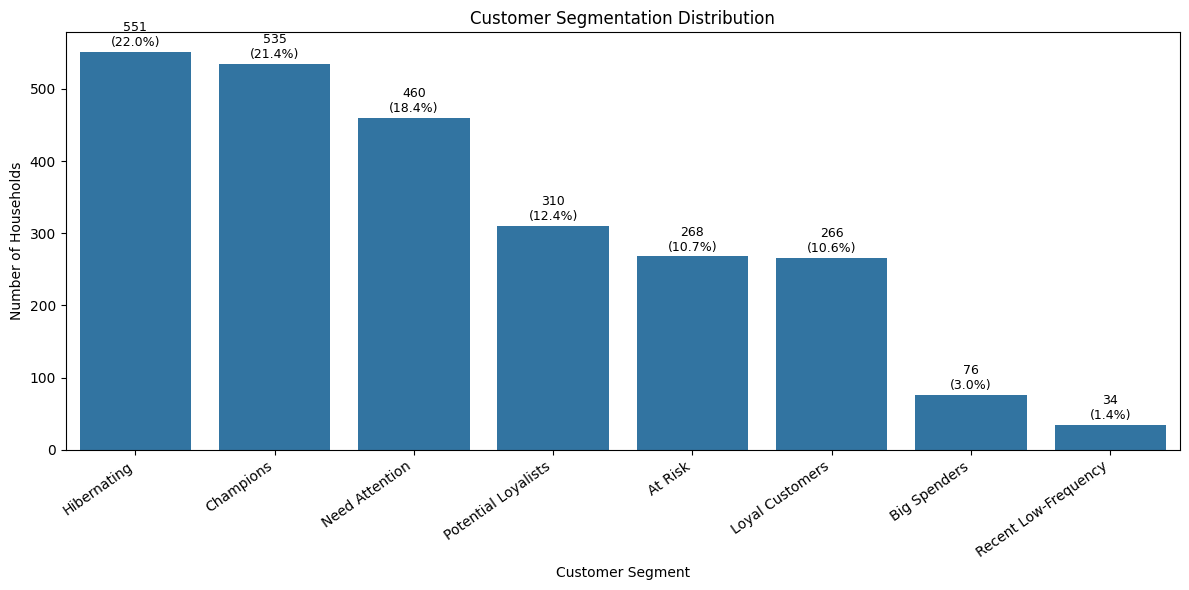

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns

segment_plot = (
    rfm_score["Segment_Final"]
    .value_counts()
    .reset_index()
)

segment_plot.columns = ["Segment", "Household_Count"]

segment_plot["Percentage"] = (
    segment_plot["Household_Count"] /
    segment_plot["Household_Count"].sum() * 100
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=segment_plot,
    x="Segment",
    y="Household_Count"
)

for i, row in segment_plot.iterrows():
    ax.text(
        i,
        row["Household_Count"] + 8,
        f'{row["Household_Count"]}\n({row["Percentage"]:.1f}%)',
        ha="center",
        fontsize=9
    )

plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Households")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Visualisasi 2 — RFM Segment Profile

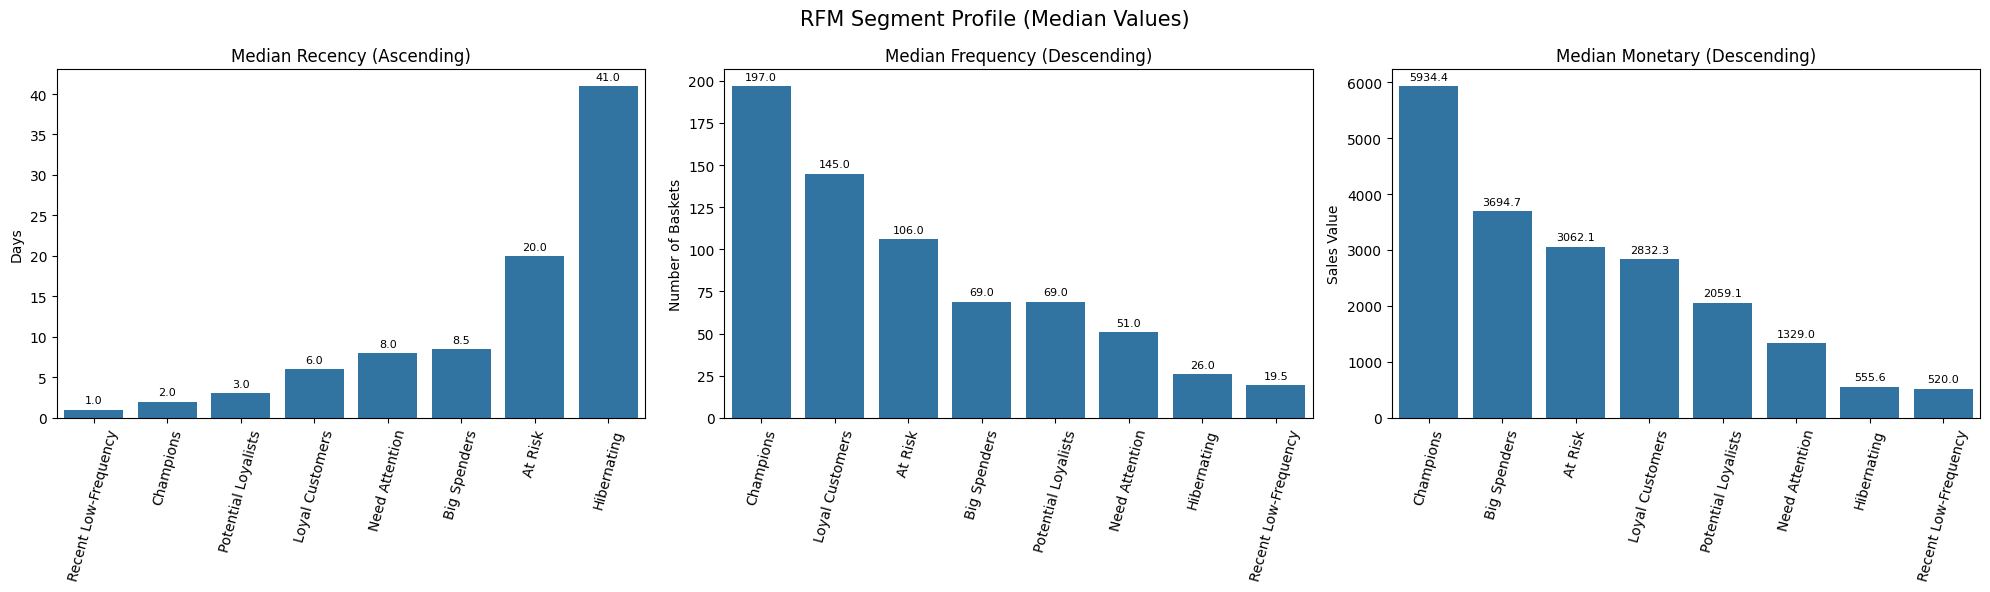

In [111]:
# Menghitung median RFM setiap segmen
rfm_profile = (
    rfm_score.groupby("Segment_Final")
    .agg(
        Recency=("Recency", "median"),
        Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median")
    )
    .reset_index()
)

# Membuat urutan masing-masing metrik
recency_order = (
    rfm_profile.sort_values("Recency", ascending=True)
    ["Segment_Final"].tolist()
)

frequency_order = (
    rfm_profile.sort_values("Frequency", ascending=False)
    ["Segment_Final"].tolist()
)

monetary_order = (
    rfm_profile.sort_values("Monetary", ascending=False)
    ["Segment_Final"].tolist()
)

# Membuat tiga grafik
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.barplot(
    data=rfm_profile,
    x="Segment_Final",
    y="Recency",
    order=recency_order,
    ax=axes[0]
)
axes[0].set_title("Median Recency (Ascending)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Days")

sns.barplot(
    data=rfm_profile,
    x="Segment_Final",
    y="Frequency",
    order=frequency_order,
    ax=axes[1]
)
axes[1].set_title("Median Frequency (Descending)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of Baskets")

sns.barplot(
    data=rfm_profile,
    x="Segment_Final",
    y="Monetary",
    order=monetary_order,
    ax=axes[2]
)
axes[2].set_title("Median Monetary (Descending)")
axes[2].set_xlabel("")
axes[2].set_ylabel("Sales Value")

# Menambahkan label angka
for ax in axes:
    ax.tick_params(axis="x", rotation=75)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f",
            padding=3,
            fontsize=8
        )

plt.suptitle("RFM Segment Profile (Median Values)", fontsize=15)
plt.tight_layout()
plt.show()

In [112]:
# Menghitung total monetary setiap segmen
monetary_contribution = (
    rfm_score.groupby("Segment_Final")
    .agg(
        Total_Monetary=("Monetary", "sum"),
        Household_Count=("household_key", "count")
    )
    .reset_index()
)

# Menghitung persentase kontribusi
total_sales = monetary_contribution["Total_Monetary"].sum()

monetary_contribution["Contribution_Percentage"] = (
    monetary_contribution["Total_Monetary"] /
    total_sales * 100
)

# Mengurutkan kontribusi terbesar
monetary_contribution = monetary_contribution.sort_values(
    "Total_Monetary",
    ascending=False
)

display(monetary_contribution)

,Segment_Final,Total_Monetary,Household_Count,Contribution_Percentage
2,Champions,3856230.02,535,47.859109
4,Loyal Customers,1132289.96,266,14.052686
0,At Risk,1007089.82,268,12.498845
6,Potential Loyalists,763089.74,310,9.470596
5,Need Attention,608729.85,460,7.554857
3,Hibernating,349176.47,551,4.333578
1,Big Spenders,319439.34,76,3.964515
7,Recent Low-Frequency,21417.88,34,0.265814


Visualisasi 3 - Monetary Contribution

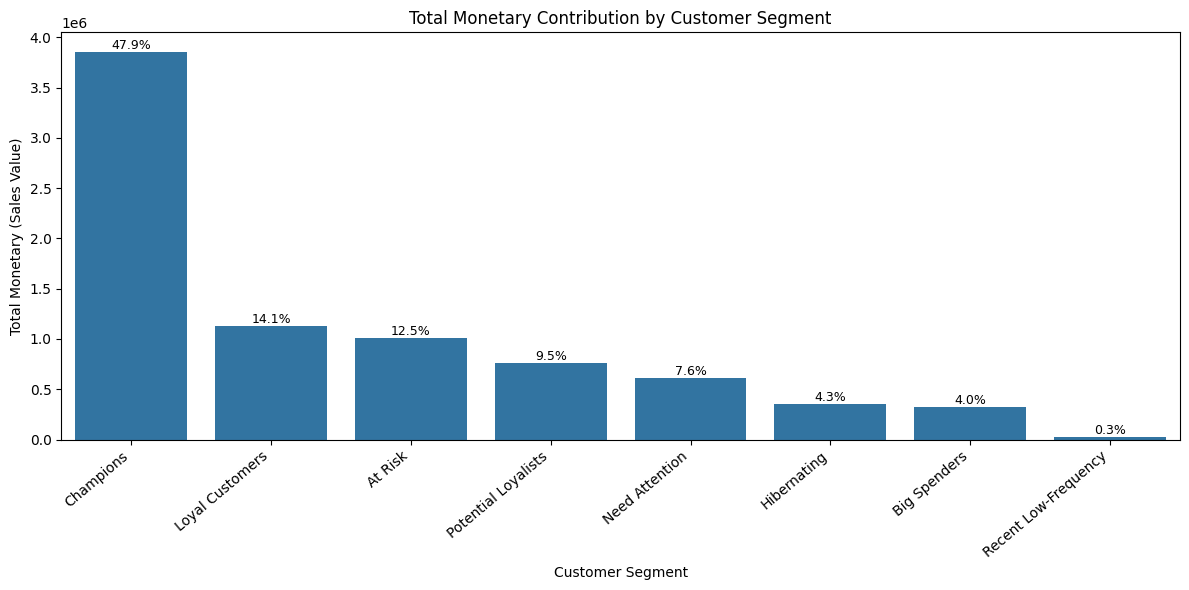

In [113]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=monetary_contribution,
    x="Segment_Final",
    y="Total_Monetary"
)

for i, row in monetary_contribution.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row["Total_Monetary"],
        f'{row["Contribution_Percentage"]:.1f}%',
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Total Monetary Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Monetary (Sales Value)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

Visualisasi 4 - RFM Segement Heatmap

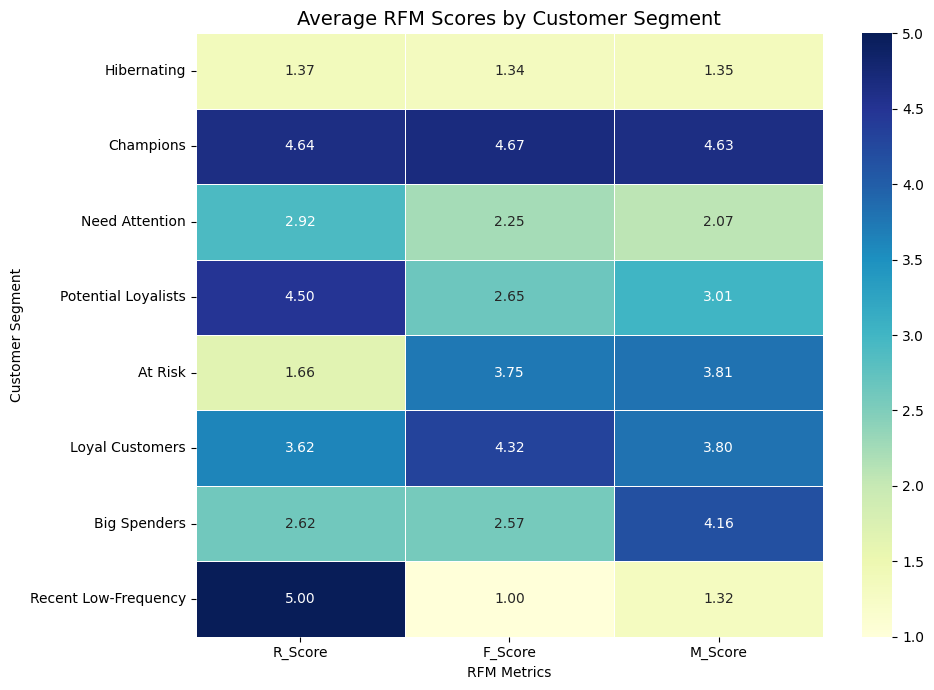

In [115]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung rata-rata skor RFM setiap segmen
rfm_heatmap = (
    rfm_score.groupby("Segment_Final")[
        ["R_Score", "F_Score", "M_Score"]
    ]
    .mean()
)

# Mengurutkan segmen berdasarkan jumlah household
segment_order = (
    rfm_score["Segment_Final"]
    .value_counts()
    .index
)

rfm_heatmap = rfm_heatmap.reindex(segment_order)

# Membuat heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    rfm_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=1,
    vmax=5
)

plt.title("Average RFM Scores by Customer Segment", fontsize=14)
plt.xlabel("RFM Metrics")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()